# LLMnetopsLab v2 — Results Visualization

Visualizations of 50 unattended runs where Claude Code (Opus 4.6, effort medium) troubleshot a 19-device multi-area OSPF / eBGP lab in GNS3 with 12 injected faults across VyOS, MikroTik RouterOS and Alpine Linux.

Data comes from three scripts in `scripts/validation/`:

- `validate_runs.py` checks that every run is valid (one session, right model, lab broke the same way, no stray file reads, no management-plane changes, and so on).
- `analyze_runs.py` reads the commands each agent sent: when each fault's fix went out, and the workaround attempts it made along the way.
- `transcript_metrics.py` measures how each agent worked: model time against time waiting on tools, how often it issued parallel tool calls, how many of its device scripts ran threaded, and when it first used the faulty ping check.

In [1]:
import json
import subprocess
import sys
import tempfile
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
import pandas as pd
import numpy as np

# Publication-quality defaults (same as v1)
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'figure.figsize': (8, 5),
    'hatch.linewidth': 0.6,
    'patch.edgecolor': 'black',
})
sns.set_style('whitegrid')

# Paths
ROOT = Path('..').resolve()
SCRIPTS = ROOT / 'scripts'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
LABEL = 'opus'


def run_script(name):
    """Run a validation script with --json and return what it wrote.
    validate_runs.py exits 1 when any run has a FAIL, so the exit code isn't checked."""
    with tempfile.TemporaryDirectory() as tmp:
        out = Path(tmp) / 'out.json'
        result = subprocess.run([sys.executable, str(SCRIPTS / 'validation' / name), '--label', LABEL,
                                 '--json', str(out)], cwd=ROOT, capture_output=True, text=True)
        if not out.exists():
            raise RuntimeError(f'{name} failed:\n{result.stderr}')
        return json.loads(out.read_text())


validation = run_script('validate_runs.py')
analysis = run_script('analyze_runs.py')
metrics = run_script('transcript_metrics.py')

# Cost comes from validate_runs.py, which keeps it unrounded (analyze_runs.py rounds to the cent)
df = (pd.DataFrame(analysis).drop(columns=['minutes', 'cost'])
      .merge(pd.DataFrame(metrics), on='run')
      .merge(pd.DataFrame([{'run': r['run'], 'status': r['status'], 'cost': r['cost'],
                            'agent_leftovers': len(r['workarounds_real']),
                            'platform_leftovers': r['workarounds_benign']} for r in validation['runs']]), on='run'))
df['area20_minutes'] = df['area20_minutes'].fillna(0)
df['run_no'] = df['run'].str[-3:].astype(int)

print(f"Loaded {len(df)} runs ({validation['batch']['model_requested']}, effort {validation['batch']['effort']})")

# Store all figures for export
all_figures = []

Loaded 50 runs (claude-opus-4-6, effort medium)


## Run Validity

Every run fixed all 12 faults. The validator raised one FAIL and ten WARNs. Each was checked by hand against the transcript:

| Check | Runs | Finding |
|---|---|---|
| isolation (FAIL) | 043 | False positive: `'/export terse \| grep -i mtu'` is a RouterOS command sent over netmiko, not a host Bash call |
| mgmt | 041, 050 | False positives: a `passwd` function argument, and `grep -v reboot-on-upgrade` |
| background | 002, 036 | A leftover `until` loop woke the agent after its report; real agent time is 28.6 and 28.5 min |
| limits | 032 | One context compaction |
| device_files / frr_text | 006, 009, 019, 020, 039 | `vtysh write memory`, and in 020 a VyOS boot script on Hub-B. The next runs' baselines and FRR configs were still identical, so nothing carried over |

All 50 runs count.

## Figure 1 — Validation Checks per Run

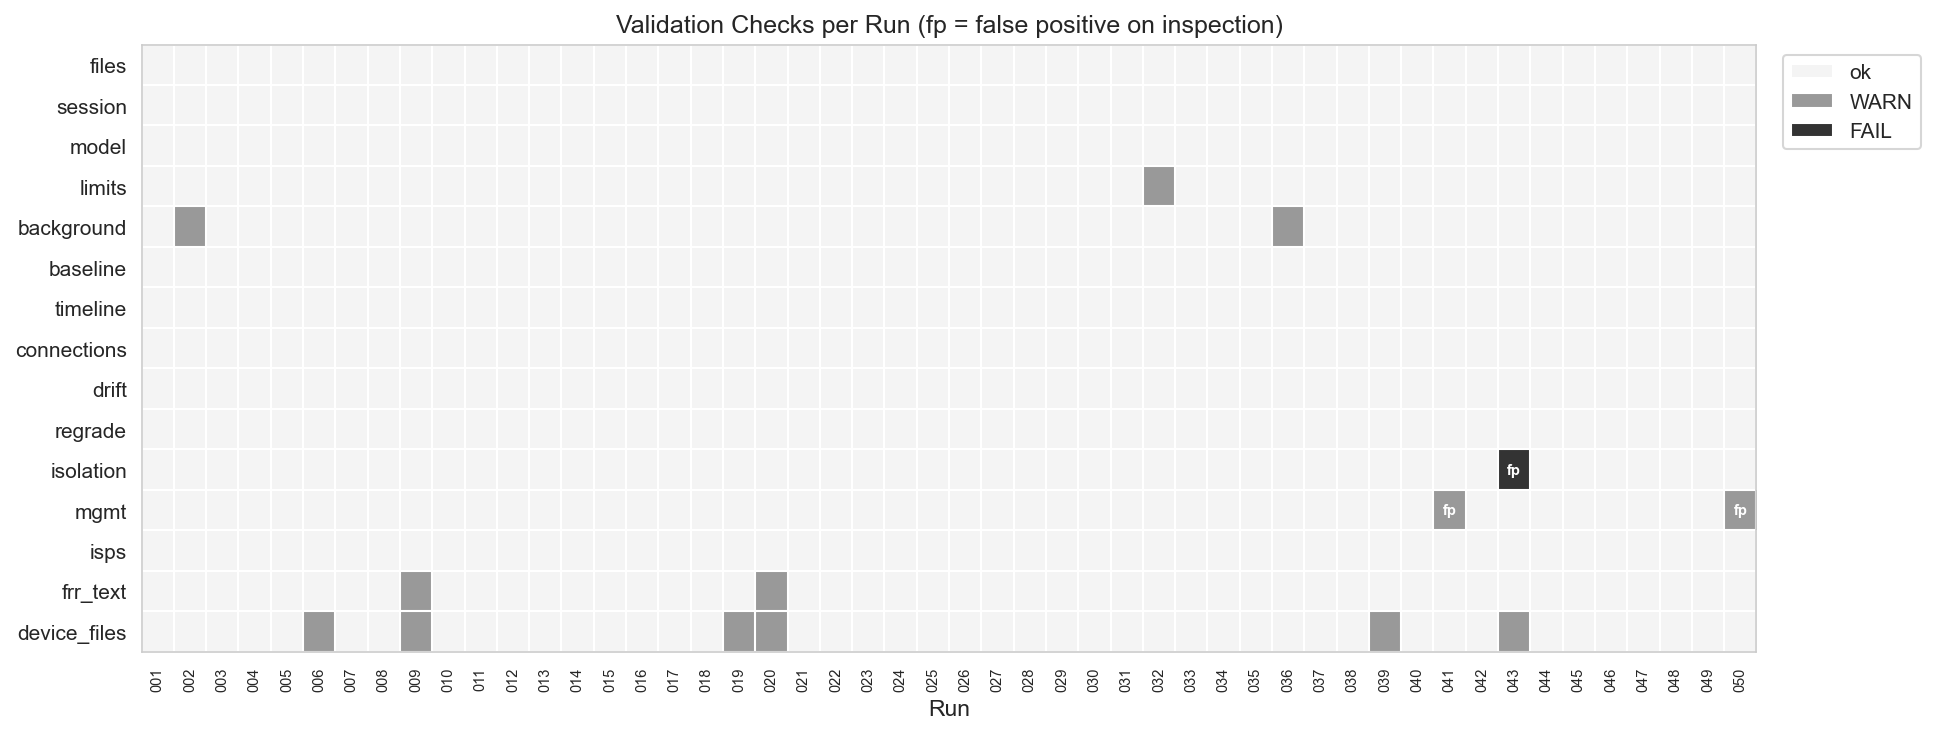

In [2]:
checks = list(validation['runs'][0]['checks'].keys())
status_code = {'ok': 0, 'WARN': 1, 'FAIL': 2}
# Flags shown to be false positives on inspection (see the table above)
FALSE_POSITIVES = {('run_043', 'isolation'), ('run_041', 'mgmt'), ('run_050', 'mgmt')}

grid = np.array([[status_code[r['checks'][c]['status']] for r in validation['runs']] for c in checks])
fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(grid, cmap=ListedColormap(['#f4f4f4', '#999999', '#333333']), vmin=0, vmax=2, aspect='auto')

run_names = [r['run'] for r in validation['runs']]
for run, check in FALSE_POSITIVES:
    ax.text(run_names.index(run), checks.index(check), 'fp', ha='center', va='center', fontsize=7,
            color='white', fontweight='bold')

ax.set_xticks(np.arange(len(run_names)))
ax.set_xticklabels([r[-3:] for r in run_names], rotation=90, fontsize=7)
ax.set_yticks(np.arange(len(checks)))
ax.set_yticklabels(checks)
ax.set_xticks(np.arange(-.5, len(run_names)), minor=True)
ax.set_yticks(np.arange(-.5, len(checks)), minor=True)
ax.grid(which='minor', color='white', linewidth=1)
ax.grid(which='major', visible=False)
ax.tick_params(which='minor', length=0)
ax.set_xlabel('Run')
ax.set_title('Validation Checks per Run (fp = false positive on inspection)')
ax.legend(handles=[Patch(facecolor='#f4f4f4', label='ok'), Patch(facecolor='#999999', label='WARN'),
                   Patch(facecolor='#333333', label='FAIL')],
          loc='upper left', bbox_to_anchor=(1.01, 1), frameon=True)

plt.tight_layout()
all_figures.append(('fig1_validation_matrix', fig))
plt.show()

## Figure 2 — Fault Score and End-State Cleanliness

The scorer marks a run perfect when all 12 faults are fixed, and clean when it is perfect and nothing else differs from the design. Deleting the local-preference leaves an empty `route-map ISP-B-IN rule 10 set` node in VyOS. That node is the platform's doing, not the agent's, so it is counted separately.

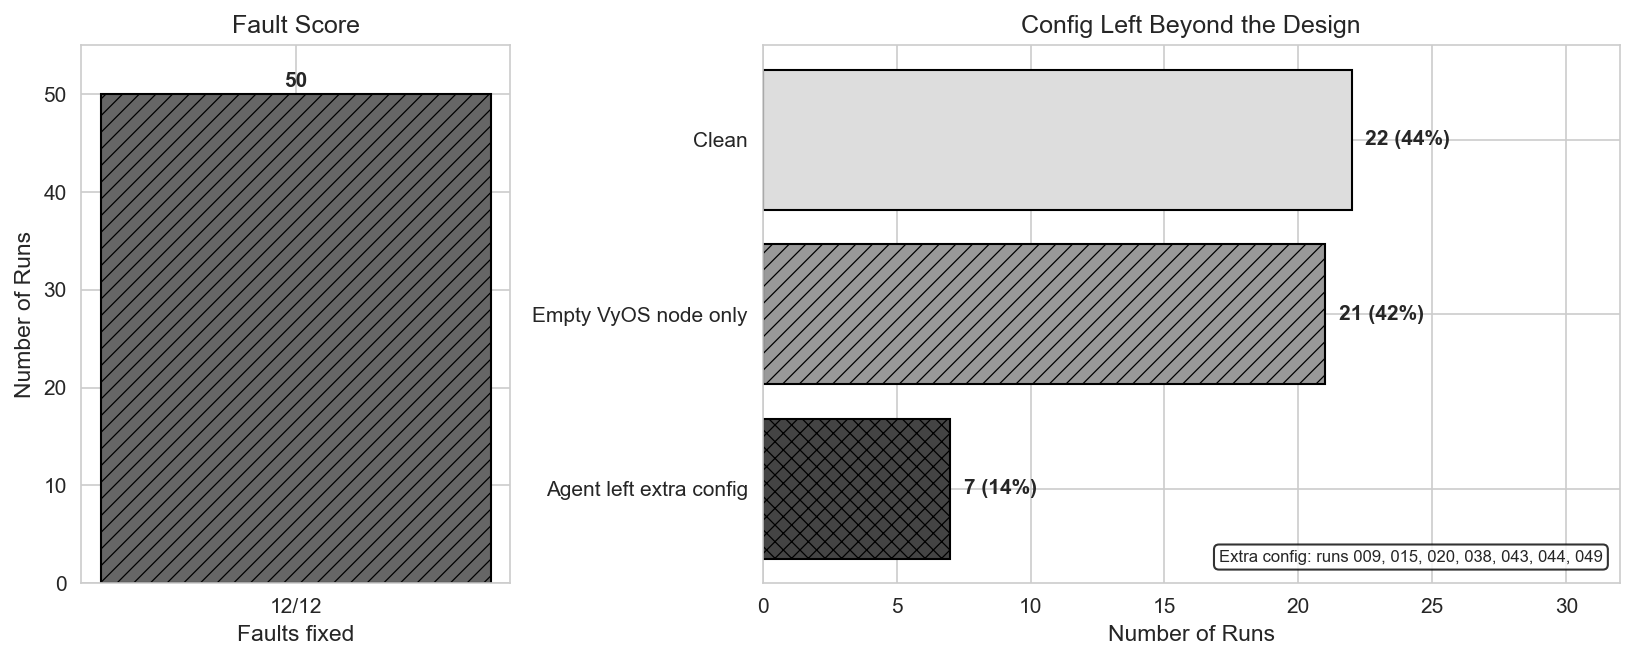

In [3]:
def cleanliness(row):
    if row['agent_leftovers']:
        return 'Agent left extra config'
    if row['platform_leftovers']:
        return 'Empty VyOS node only'
    return 'Clean'

df['end_state'] = df.apply(cleanliness, axis=1)
order = ['Clean', 'Empty VyOS node only', 'Agent left extra config']
styles = {'Clean': ('#dddddd', ''), 'Empty VyOS node only': ('#999999', '///'),
          'Agent left extra config': ('#444444', 'xxx')}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={'width_ratios': [1, 2]})

scores = df['fixed'].value_counts().sort_index()
for i, (s, v) in enumerate(scores.items()):
    ax1.bar(f'{s}/12', v, color='#666666', edgecolor='black', hatch='///')
    ax1.text(i, v + 0.8, str(v), ha='center', fontweight='bold')
ax1.set_ylim(0, 55)
ax1.set_xlabel('Faults fixed')
ax1.set_ylabel('Number of Runs')
ax1.set_title('Fault Score')

counts = df['end_state'].value_counts().reindex(order, fill_value=0)
for i, (k, v) in enumerate(counts.items()):
    color, hatch = styles[k]
    ax2.barh(k, v, color=color, edgecolor='black', hatch=hatch)
    ax2.text(v + 0.5, i, f'{v} ({v*2}%)', va='center', fontweight='bold')
leftover_runs = ', '.join(df.loc[df['agent_leftovers'] > 0, 'run'].str[-3:])
ax2.text(0.98, 0.04, f'Extra config: runs {leftover_runs}', transform=ax2.transAxes, ha='right', fontsize=8,
         bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.8))
ax2.set_xlim(0, 32)
ax2.invert_yaxis()
ax2.set_xlabel('Number of Runs')
ax2.set_title('Config Left Beyond the Design')

plt.tight_layout()
all_figures.append(('fig2_score_cleanliness', fig))
plt.show()

## Figure 3 — Duration and Cost Distributions

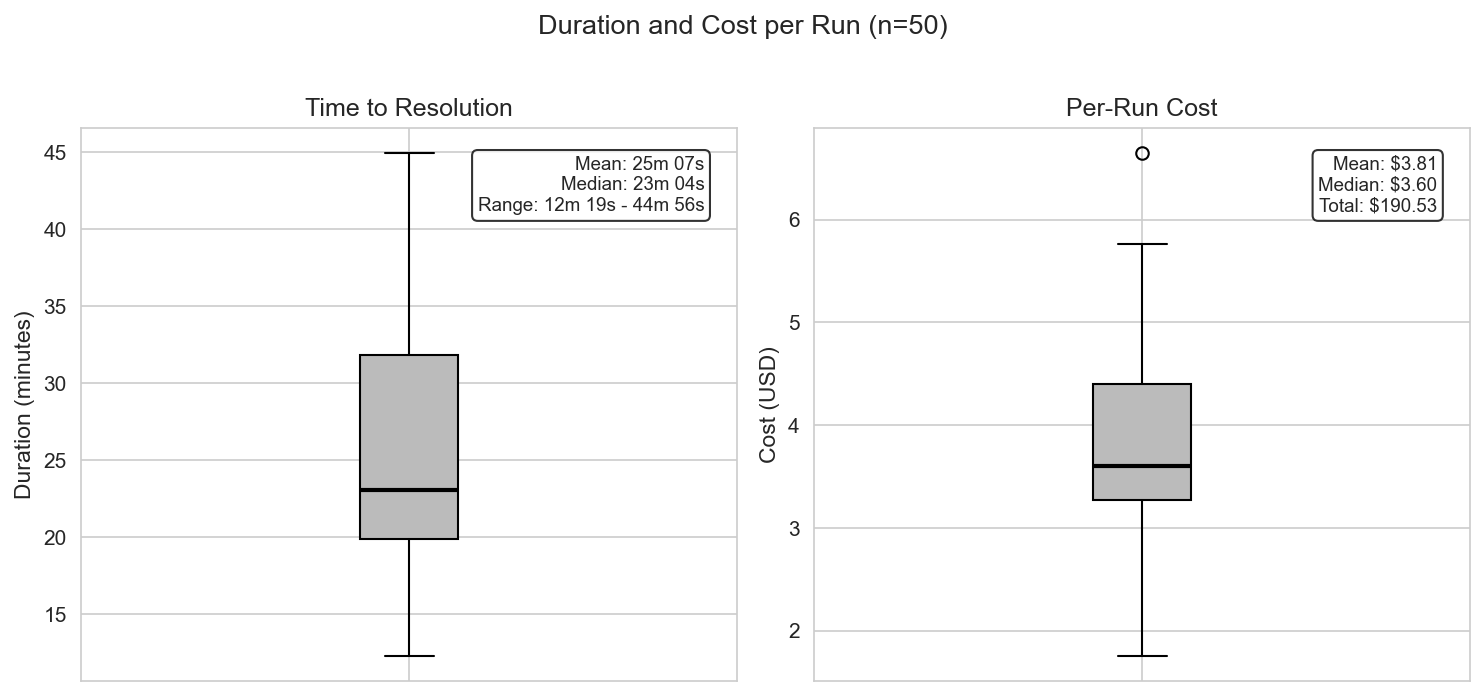

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

def fmt_time(m):
    return f'{int(m)}m {int(round(m % 1 * 60)):02d}s'

def fmt_cost(v):
    return f'${v:.2f}'

for ax, values, ylabel, title, fmt, extra in [
        (ax1, df['wall_min'], 'Duration (minutes)', 'Time to Resolution', fmt_time,
         f"Range: {fmt_time(df['wall_min'].min())} - {fmt_time(df['wall_min'].max())}"),
        (ax2, df['cost'], 'Cost (USD)', 'Per-Run Cost', fmt_cost, f"Total: ${df['cost'].sum():.2f}")]:
    ax.boxplot(values, vert=True, patch_artist=True,
               boxprops=dict(facecolor='#bbbbbb', edgecolor='black'),
               medianprops=dict(color='black', linewidth=2))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticklabels([''])
    ax.text(0.95, 0.95, f"Mean: {fmt(values.mean())}\nMedian: {fmt(values.median())}\n{extra}",
            transform=ax.transAxes, fontsize=9, va='top', ha='right',
            bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.8))

fig.suptitle('Duration and Cost per Run (n=50)', fontsize=13, y=1.02)
plt.tight_layout()
all_figures.append(('fig3_duration_cost', fig))
plt.show()

## Figure 4 — Anatomy of a Run

Each bar is one run, sorted by duration. The fixing window runs from the first fix sent to the last of the 12. Every run gets through it in the first few minutes. The rest of the run is verification, plus two detours:

- **The area-20 quirk.** In the correct lab, FRR on Hub-B still leaks the area-20 /24s into area 10 and 10.1.0.0/16 into totally stubby area 20. The design says neither should happen, and no configuration change makes them go away.
- **A bug in the agent's own ping check.** The agent tested reachability with `"0% packet loss" in out`, which also matches "100% packet loss", so blocked guest traffic looked reachable.

The quirk span runs from the first assistant message about it to the last, so it can overlap verification work. Bars use the wall-clock session (`agent_started` to `agent_ended`), which is what the transcript timestamps are measured against. From run 019 onward, that is 0.5–3 min longer than `run_agent.py`'s monotonic `wall_seconds`, which the other figures use.

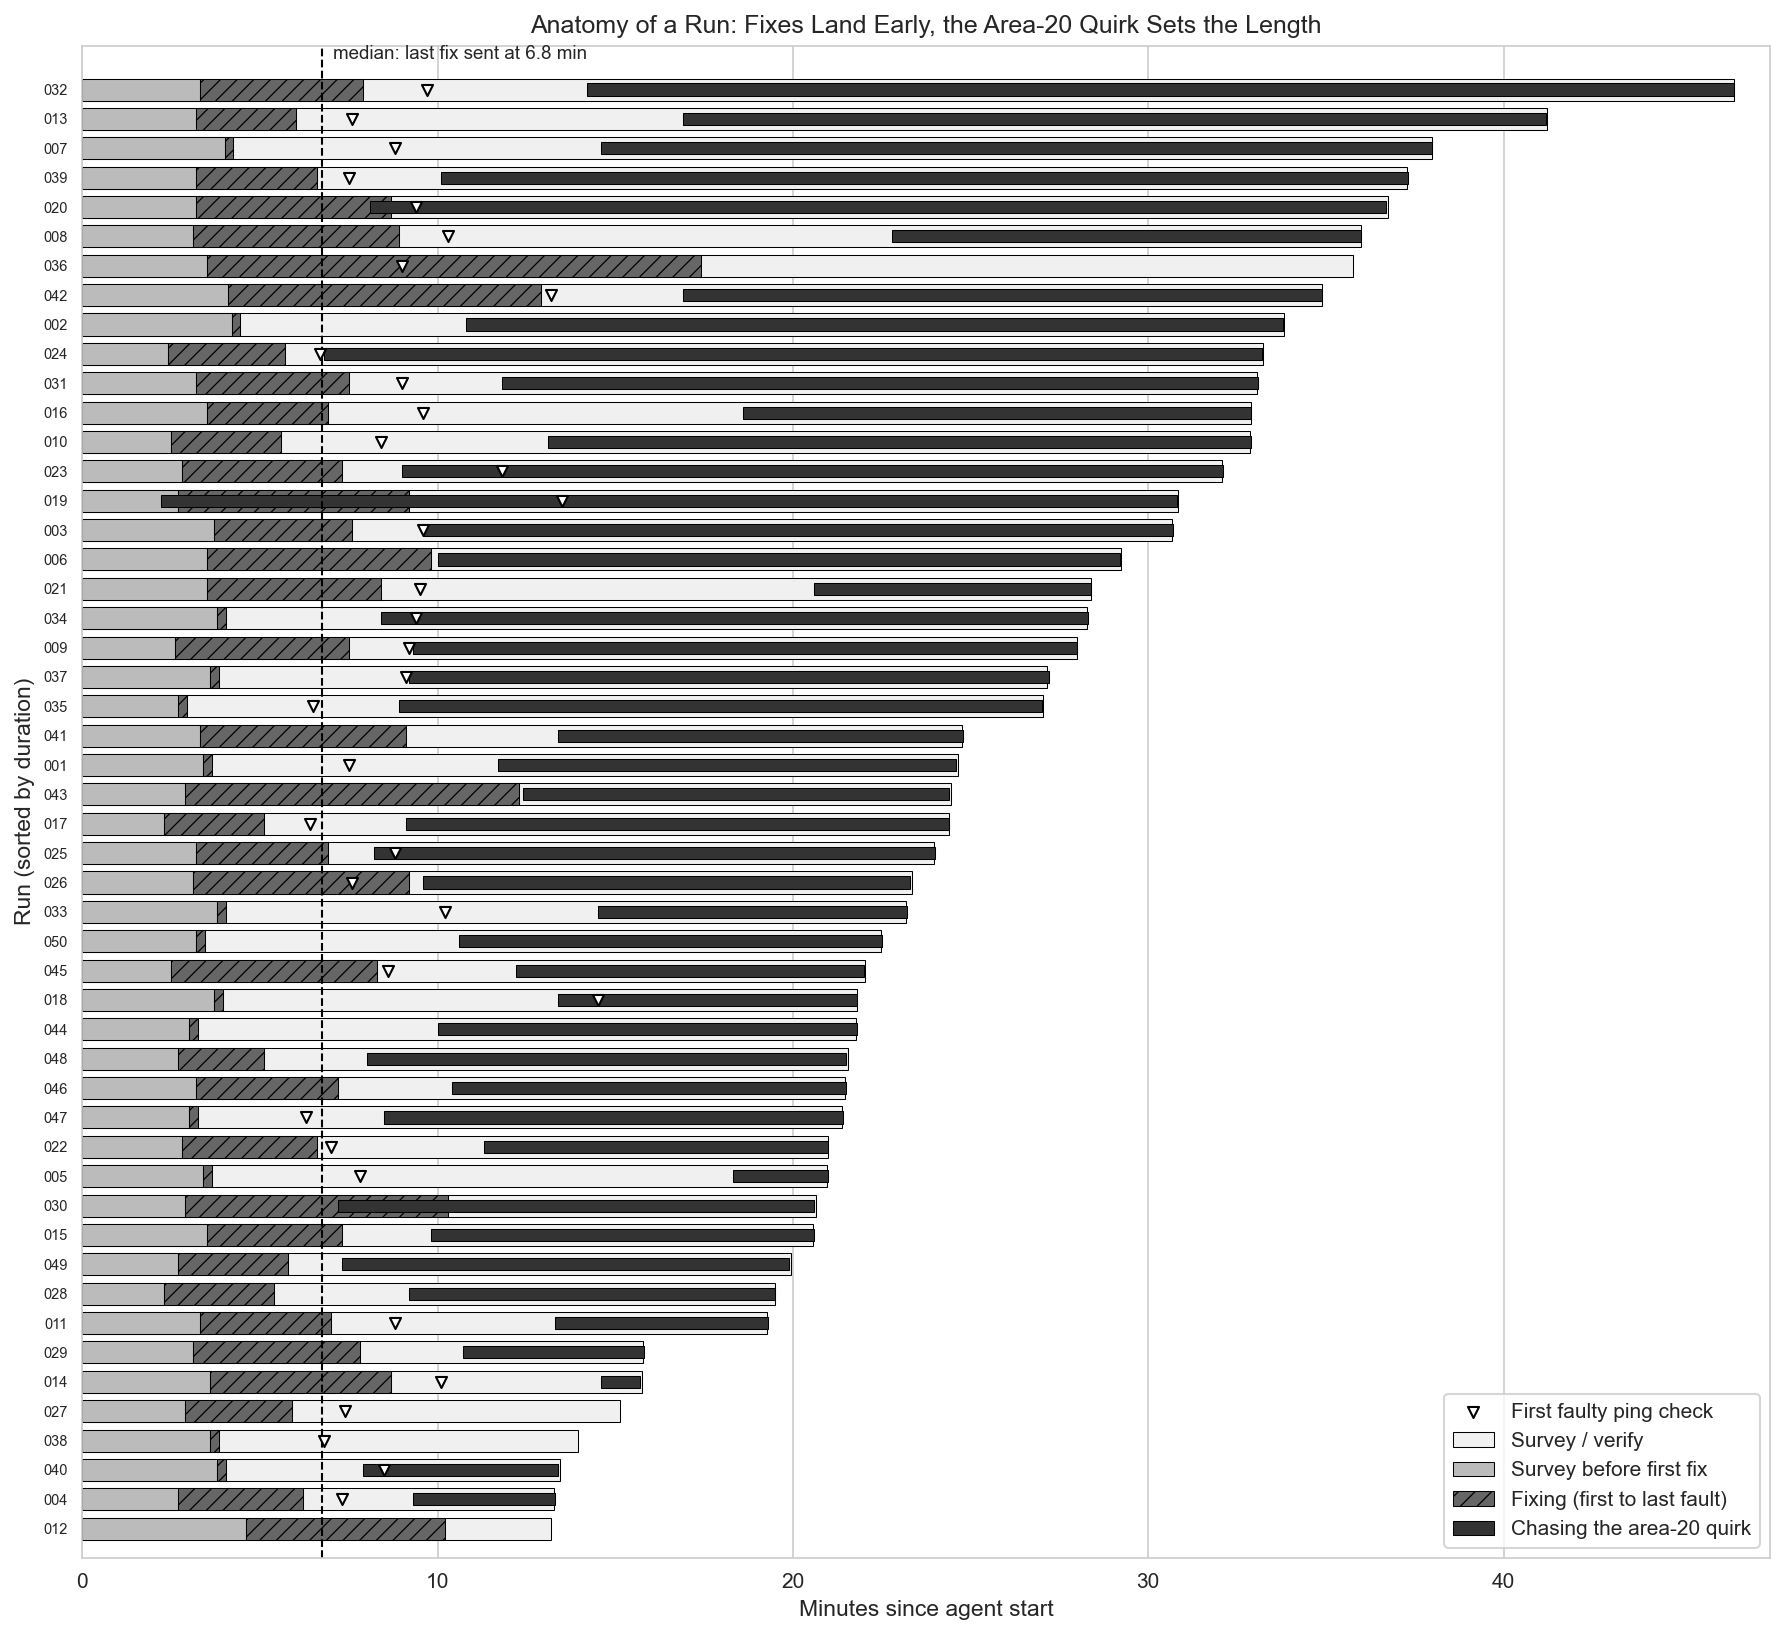

In [5]:
tl = df.sort_values('session_min').reset_index(drop=True)
fix_end = tl['fix_minutes'].apply(lambda d: max(d.values()) if d else np.nan)
# Runs that sent every fix from one script get a sliver so the window stays visible
fix_width = (fix_end - tl['first_fix_min']).clip(lower=0.25)
fig, ax = plt.subplots(figsize=(12, 11))
y = np.arange(len(tl))
h = 0.75

ax.barh(y, tl['session_min'], h, color='#f0f0f0', edgecolor='black', linewidth=0.5, label='Survey / verify')
ax.barh(y, tl['first_fix_min'], h, color='#bbbbbb', edgecolor='black', linewidth=0.5, label='Survey before first fix')
ax.barh(y, fix_width, h, left=tl['first_fix_min'], color='#666666',
        edgecolor='black', linewidth=0.5, hatch='///', label='Fixing (first to last fault)')
a20 = (tl['area20_minutes'] > 0).to_numpy()
ax.barh(y[a20], tl.loc[a20, 'area20_minutes'], h * 0.55, left=tl.loc[a20, 'area20_first_min'],
        color='#333333', edgecolor='black', linewidth=0.5, label='Chasing the area-20 quirk')
bug = tl['ping_bug_min'].notna().to_numpy()
ax.scatter(tl.loc[bug, 'ping_bug_min'], y[bug], marker='v', s=28, color='white', edgecolor='black', zorder=5,
           label='First faulty ping check')

ax.set_yticks(y)
ax.set_yticklabels(tl['run'].str[-3:], fontsize=7)
ax.set_xlabel('Minutes since agent start')
ax.set_ylabel('Run (sorted by duration)')
ax.set_title('Anatomy of a Run: Fixes Land Early, the Area-20 Quirk Sets the Length')
ax.set_xlim(0, tl['session_min'].max() + 1)
ax.set_ylim(-1, len(tl) + 0.5)
ax.legend(loc='lower right', frameon=True)
ax.grid(axis='y', visible=False)

med_fix = fix_end.median()
ax.axvline(med_fix, color='black', linestyle='--', linewidth=1)
ax.text(med_fix + 0.3, len(tl) - 0.1, f'median: last fix sent at {med_fix:.1f} min', fontsize=9, va='bottom')

plt.tight_layout()
all_figures.append(('fig4_run_anatomy', fig))
plt.show()

## Figure 5 — Run Duration vs. Time Spent on the Area-20 Quirk

The outlier at zero is run 036. It never looked at the quirk, but missed fault #12 in its survey and then overloaded SSH on the hosts with its threaded verification.

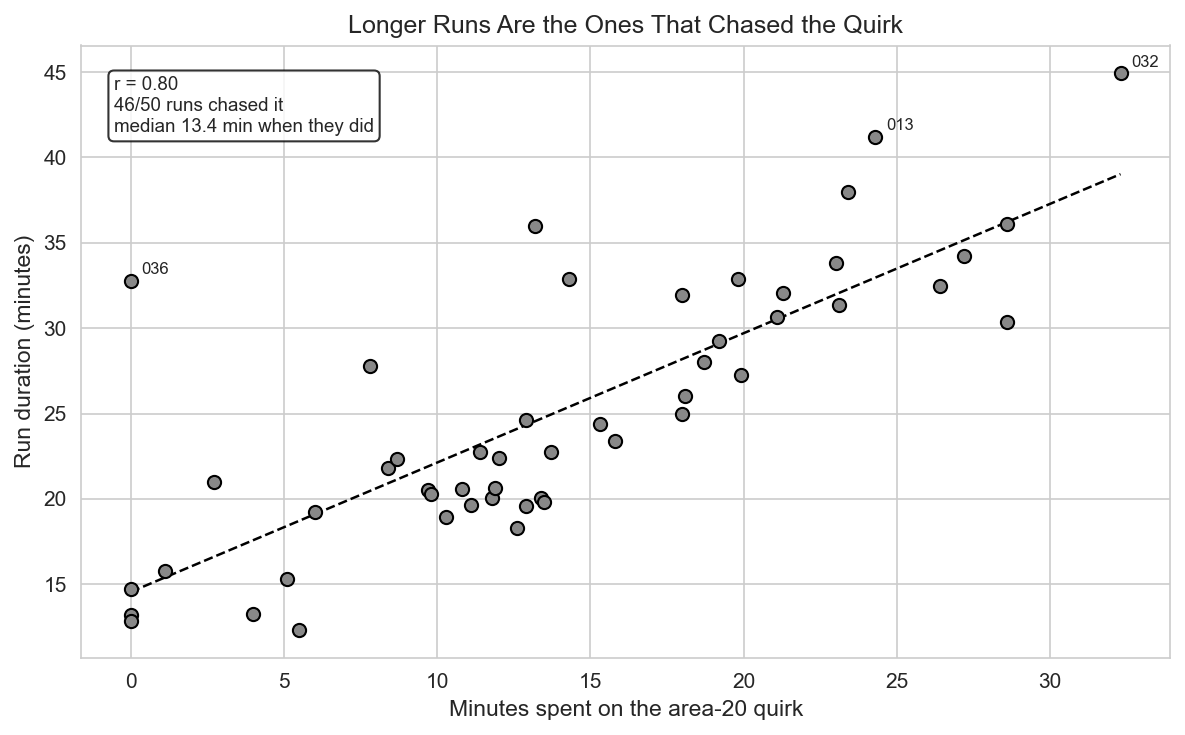

In [6]:
x, y = df['area20_minutes'], df['wall_min']
r = np.corrcoef(x, y)[0, 1]
slope, intercept = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=40, color='#888888', edgecolor='black', zorder=3)
xs = np.linspace(0, x.max(), 50)
ax.plot(xs, slope * xs + intercept, color='black', linestyle='--', linewidth=1.2)
for _, row in df[(df['wall_min'] > 38) | ((df['area20_minutes'] == 0) & (df['wall_min'] > 20))].iterrows():
    ax.annotate(row['run'][-3:], (row['area20_minutes'], row['wall_min']), textcoords='offset points',
                xytext=(5, 3), fontsize=8)

ax.set_xlabel('Minutes spent on the area-20 quirk')
ax.set_ylabel('Run duration (minutes)')
ax.set_title('Longer Runs Are the Ones That Chased the Quirk')
ax.text(0.03, 0.95, f'r = {r:.2f}\n{(x > 0).sum()}/50 runs chased it\nmedian {x[x > 0].median():.1f} min when they did',
        transform=ax.transAxes, fontsize=9, va='top',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.8))

plt.tight_layout()
all_figures.append(('fig5_duration_vs_quirk', fig))
plt.show()

## Figure 6 — When Each Fault Was Fixed

The minute each fault's fixing command was first sent, matched on command text. Faults #7 and #9 can be fixed in more than one way, so the matcher misses them in a few runs.

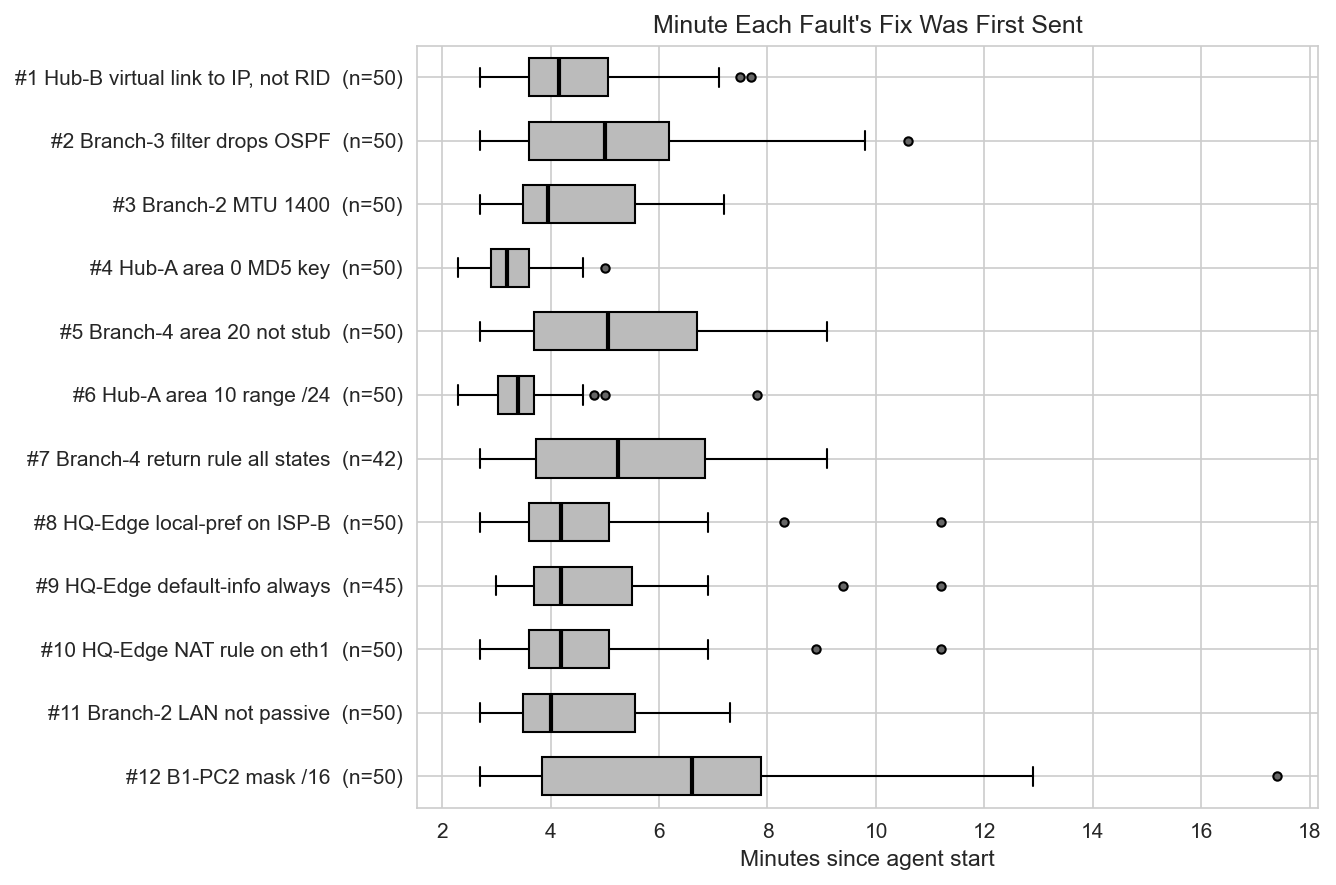

In [7]:
SHORT = {
    1: '#1 Hub-B virtual link to IP, not RID',
    2: '#2 Branch-3 filter drops OSPF',
    3: '#3 Branch-2 MTU 1400',
    4: '#4 Hub-A area 0 MD5 key',
    5: '#5 Branch-4 area 20 not stub',
    6: '#6 Hub-A area 10 range /24',
    7: '#7 Branch-4 return rule all states',
    8: '#8 HQ-Edge local-pref on ISP-B',
    9: '#9 HQ-Edge default-info always',
    10: '#10 HQ-Edge NAT rule on eth1',
    11: '#11 Branch-2 LAN not passive',
    12: '#12 B1-PC2 mask /16',
}
fix_long = pd.DataFrame([{'fault': int(f), 'minute': m} for d in df['fix_minutes'] for f, m in d.items()])
nums = sorted(SHORT)
data = [fix_long.loc[fix_long['fault'] == n, 'minute'] for n in nums]

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(data, vert=False, patch_artist=True, widths=0.6,
           boxprops=dict(facecolor='#bbbbbb', edgecolor='black'),
           medianprops=dict(color='black', linewidth=2),
           flierprops=dict(marker='o', markersize=4, markerfacecolor='#666666'))
ax.set_yticks(np.arange(1, len(nums) + 1))
ax.set_yticklabels([f'{SHORT[n]}  (n={len(d)})' for n, d in zip(nums, data)])
ax.invert_yaxis()
ax.set_xlabel('Minutes since agent start')
ax.set_title("Minute Each Fault's Fix Was First Sent")

plt.tight_layout()
all_figures.append(('fig6_fix_timing', fig))
plt.show()

## Figure 7 — Workaround Attempts

These are commands each run sent at any point, including ones it later reverted. Most belong to the escalation pattern used on the area-20 quirk: flap the range, redo it in vtysh, restart the OSPF process, then try `not-advertise` or prefix-lists and filter-lists.

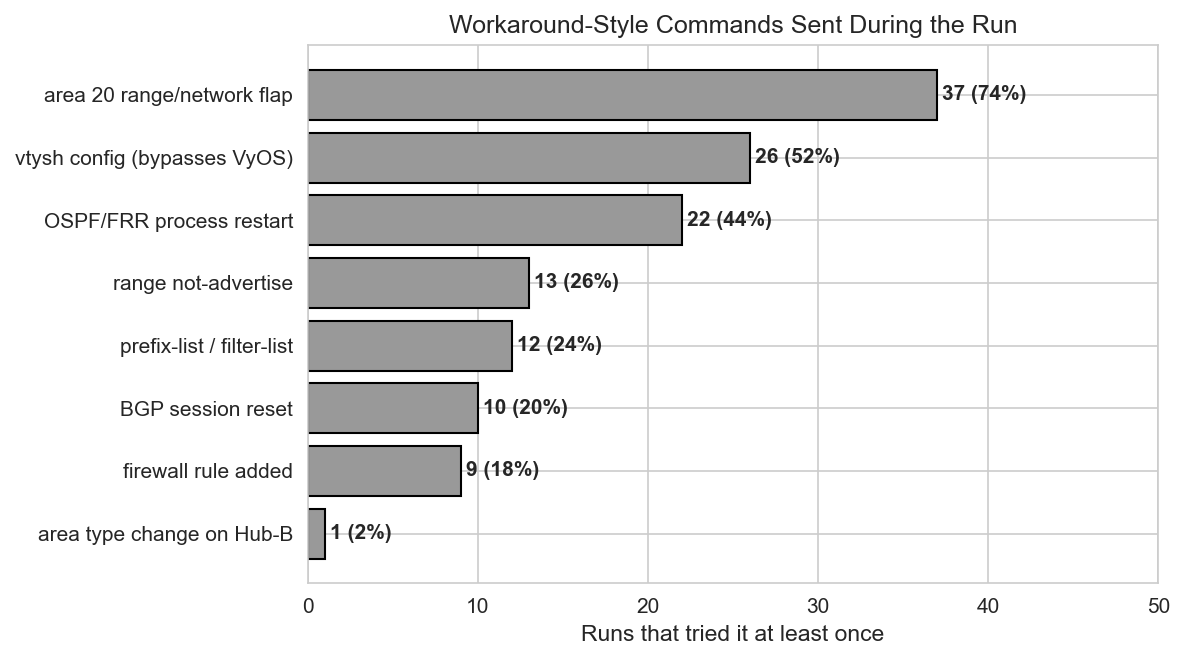

In [8]:
attempt_runs = Counter(k for a in df['attempts'] for k in a)
labels, counts = zip(*attempt_runs.most_common())

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(labels, counts, color='#999999', edgecolor='black')
for bar, count in zip(bars, counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{count} ({count*2}%)', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Runs that tried it at least once')
ax.set_title('Workaround-Style Commands Sent During the Run')
ax.set_xlim(0, 50)
ax.invert_yaxis()

plt.tight_layout()
all_figures.append(('fig7_workaround_attempts', fig))
plt.show()

## Figure 8 — Where the Wall Clock Goes

Tool calls never overlap, because no assistant message issued more than one. A run's wall clock is therefore split between waiting on the model and waiting on tools: SSH sessions, `sleep` and `until` loops for OSPF convergence, and verification passes. What remains is harness overhead.

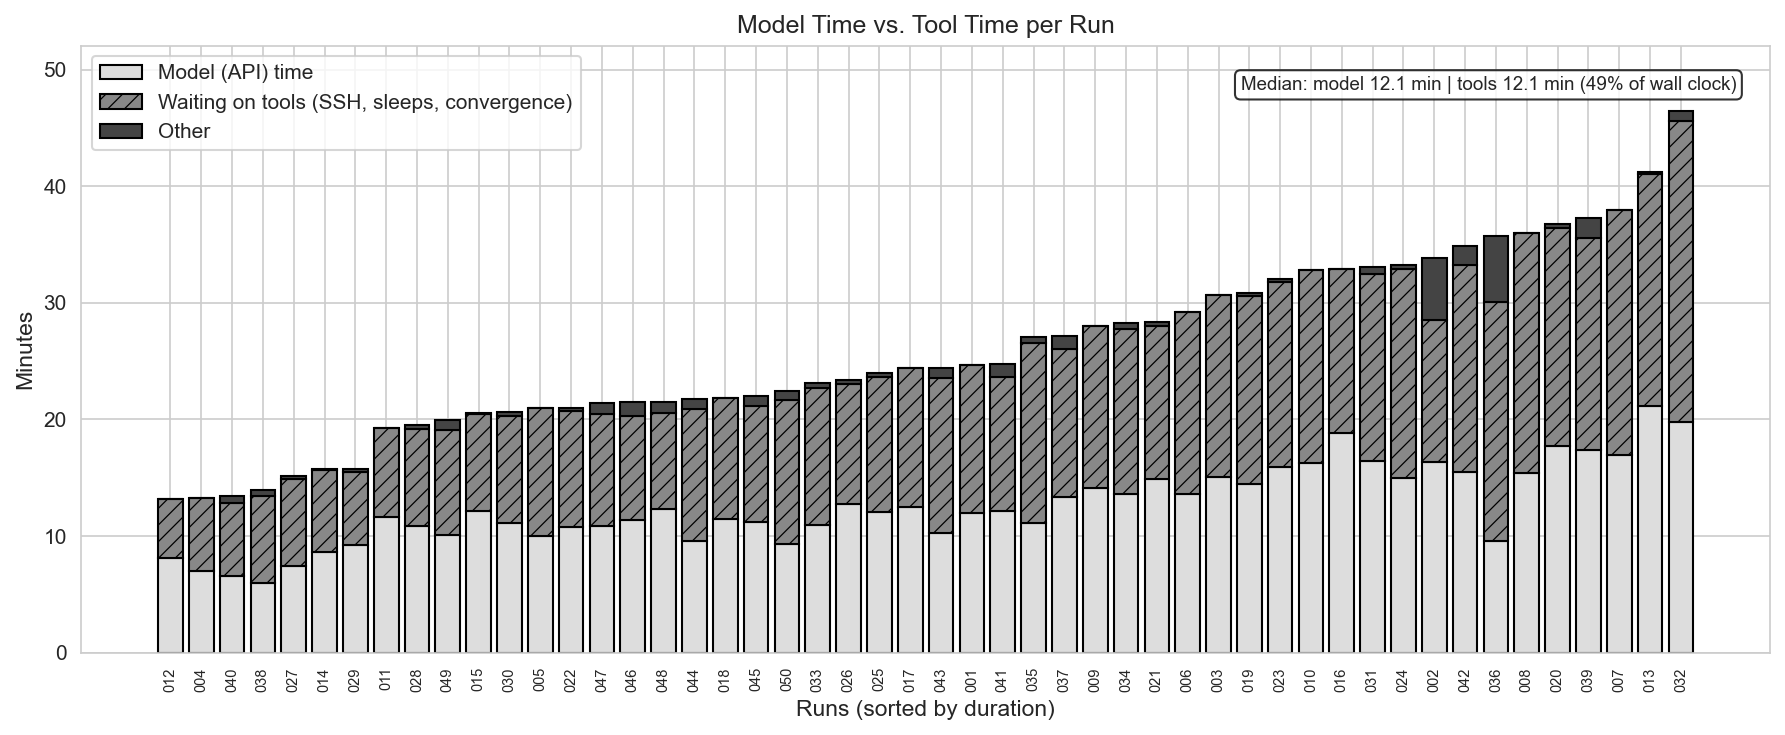

In [9]:
# Tool waits come from transcript timestamps, so the bars use the wall-clock session length
tw = df.sort_values('session_min').reset_index(drop=True)
other = (tw['session_min'] - tw['api_min'] - tw['tool_wait_min']).clip(lower=0)
x = np.arange(len(tw))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x, tw['api_min'], color='#dddddd', edgecolor='black', label='Model (API) time')
ax.bar(x, tw['tool_wait_min'], bottom=tw['api_min'], color='#888888', edgecolor='black', hatch='///',
       label='Waiting on tools (SSH, sleeps, convergence)')
ax.bar(x, other, bottom=tw['api_min'] + tw['tool_wait_min'], color='#444444', edgecolor='black', label='Other')
ax.set_xticks(x)
ax.set_xticklabels(tw['run'].str[-3:], rotation=90, fontsize=7)
ax.set_xlabel('Runs (sorted by duration)')
ax.set_ylabel('Minutes')
ax.set_title('Model Time vs. Tool Time per Run')
ax.legend(loc='upper left')
share = (df['tool_wait_min'] / df['session_min']).median() * 100
ax.set_ylim(0, tw['session_min'].max() * 1.12)
ax.text(0.98, 0.95, f"Median: model {df['api_min'].median():.1f} min | tools {df['tool_wait_min'].median():.1f} min "
        f"({share:.0f}% of wall clock)", transform=ax.transAxes, fontsize=9, ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.8))

plt.tight_layout()
all_figures.append(('fig8_time_breakdown', fig))
plt.show()

## Figure 9 — How Parallel the Work Is

The agent works in parallel only inside the Python scripts it writes. Every run threads its first survey of all 19 devices and its full verification passes (ThreadPoolExecutor over netmiko). Fixes and follow-up checks go out one device at a time. At the tool level, nothing runs in parallel at all.

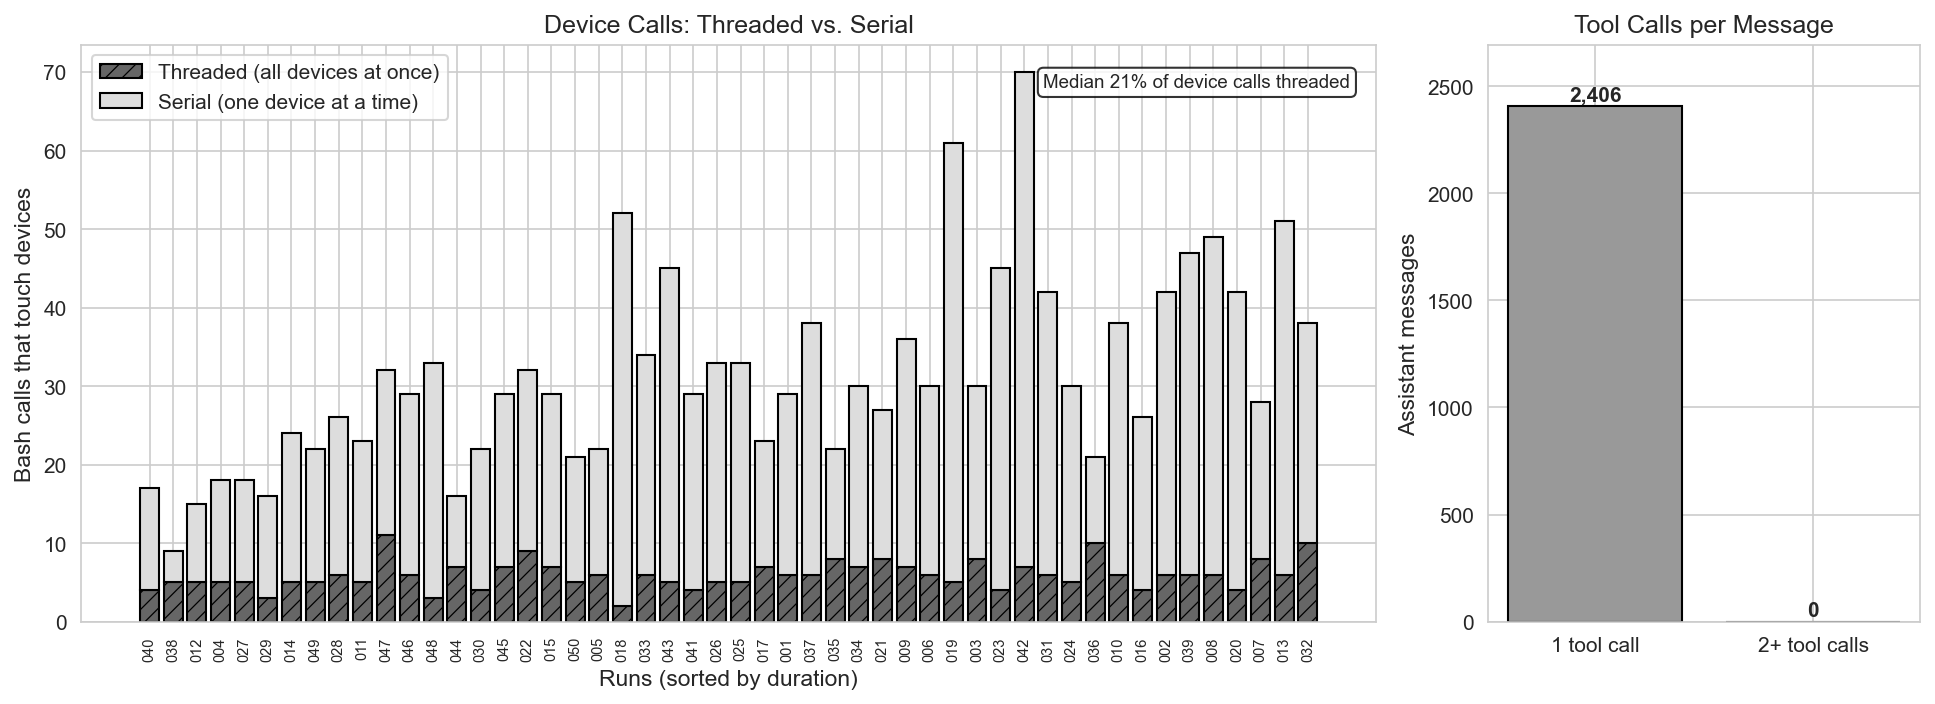

In [10]:
pw = df.sort_values('wall_min').reset_index(drop=True)
x = np.arange(len(pw))
total_msgs, multi_msgs = df['messages_with_tools'].sum(), df['multi_tool_messages'].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [3, 1]})
ax1.bar(x, pw['threaded_calls'], color='#666666', edgecolor='black', hatch='///', label='Threaded (all devices at once)')
ax1.bar(x, pw['device_calls'] - pw['threaded_calls'], bottom=pw['threaded_calls'], color='#dddddd',
        edgecolor='black', label='Serial (one device at a time)')
ax1.set_xticks(x)
ax1.set_xticklabels(pw['run'].str[-3:], rotation=90, fontsize=7)
ax1.set_xlabel('Runs (sorted by duration)')
ax1.set_ylabel('Bash calls that touch devices')
ax1.set_title('Device Calls: Threaded vs. Serial')
ax1.legend(loc='upper left')
share = (df['threaded_calls'] / df['device_calls']).median() * 100
ax1.text(0.98, 0.95, f'Median {share:.0f}% of device calls threaded', transform=ax1.transAxes, fontsize=9,
         ha='right', va='top', bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.8))

msg_counts = [total_msgs - multi_msgs, multi_msgs]
ax2.bar(['1 tool call', '2+ tool calls'], msg_counts, color=['#999999', '#444444'], edgecolor='black')
for i, v in enumerate(msg_counts):
    ax2.text(i, v + total_msgs * 0.01, f'{v:,}', ha='center', fontweight='bold')
ax2.set_ylabel('Assistant messages')
ax2.set_title('Tool Calls per Message')
ax2.set_ylim(0, total_msgs * 1.12)

plt.tight_layout()
all_figures.append(('fig9_parallelism', fig))
plt.show()

## Figure 10 — The Faulty Ping Check

36 of 50 runs wrote the same check, `"0% packet loss" in out`, independently. Because it also matches "100% packet loss", the Branch-4 guest-isolation rules looked broken when they were working. Runs that printed the raw ping output found the bug in a minute or two. Runs that blamed connection tracking or parallel SSH first lost up to 20 minutes.

Duration is also driven by the area-20 quirk, so treat the comparison as descriptive.

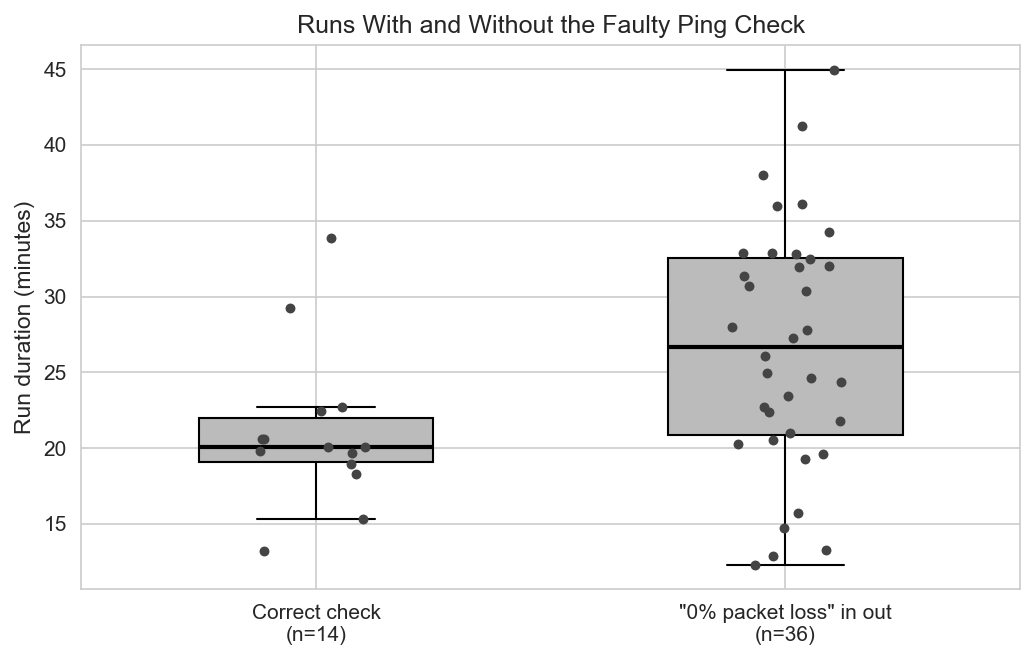

In [11]:
df['ping_bug'] = df['ping_bug_min'].notna()
groups = [df.loc[~df['ping_bug'], 'wall_min'], df.loc[df['ping_bug'], 'wall_min']]
labels = [f'Correct check\n(n={len(groups[0])})', f'"0% packet loss" in out\n(n={len(groups[1])})']

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(groups, patch_artist=True, widths=0.5,
           boxprops=dict(facecolor='#bbbbbb', edgecolor='black'),
           medianprops=dict(color='black', linewidth=2), showfliers=False)
rng = np.random.default_rng(0)
for i, g in enumerate(groups, start=1):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(g)), g, s=14, color='#444444', zorder=3)
ax.set_xticks([1, 2])
ax.set_xticklabels(labels)
ax.set_ylabel('Run duration (minutes)')
ax.set_title('Runs With and Without the Faulty Ping Check')

plt.tight_layout()
all_figures.append(('fig10_ping_check', fig))
plt.show()

## Figure 11 — How Accurately the Final Report Describes the Quirk

These labels come from reading each run's final report by hand. They are not computed. A report counts as accurate when it names both leaks (the area-20 /24s in area 10, and 10.1.0.0/16 in totally stubby area 20) as unresolved. It can be accurate and still blame FRR.

- **Missed one leak:** usually it calls 10.1.0.0/16 on Branch-4 "correct for totally stubby".
- **Misdiagnosed:** it calls the leaks stale LSAs that will age out.
- **Reported nothing:** it says nothing is unresolved.

The fastest runs are mostly the ones that never examined the anomaly.

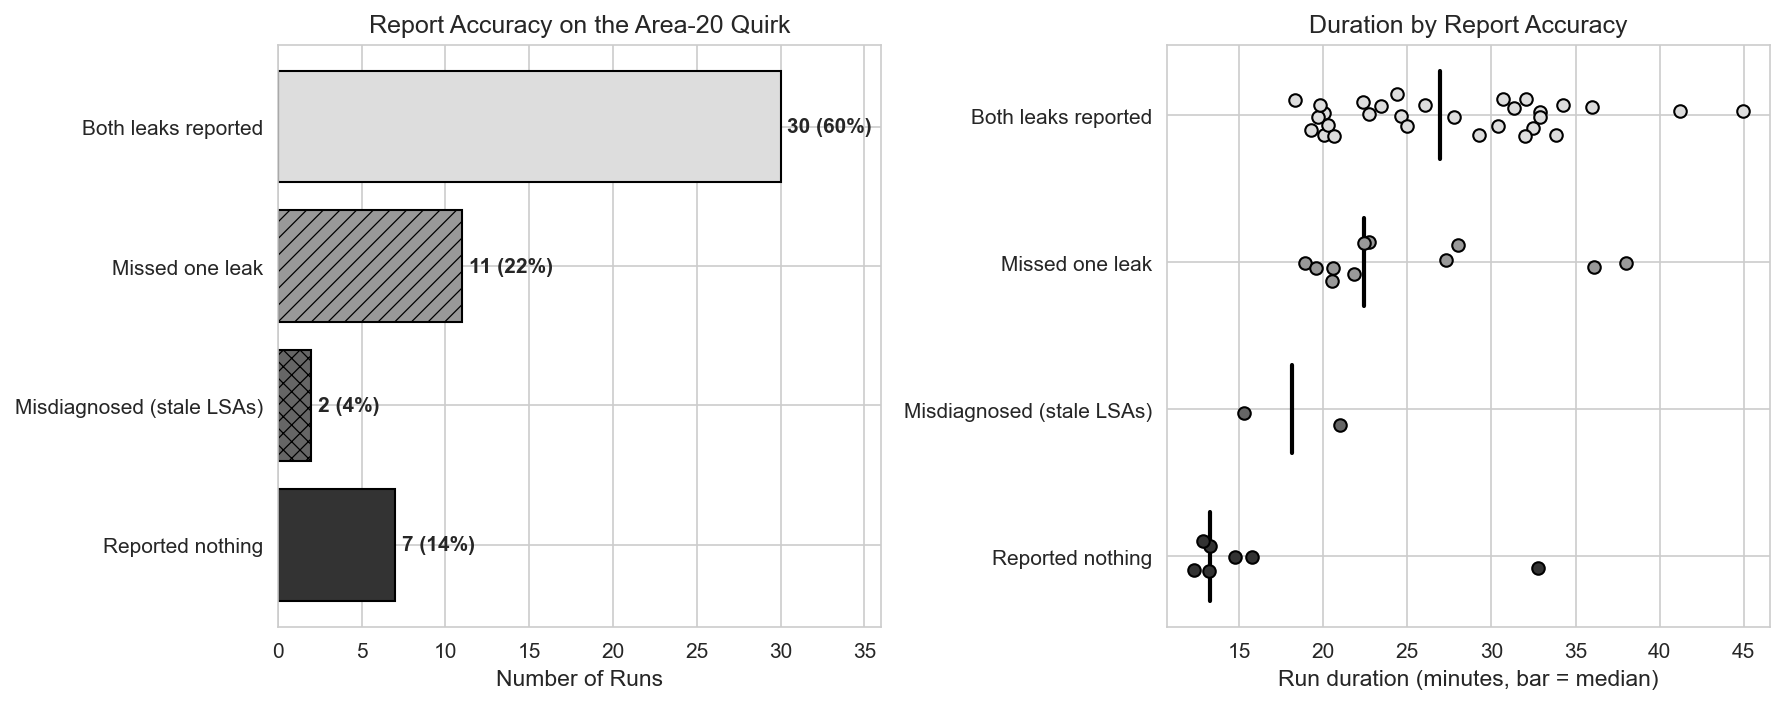

In [12]:
REPORT_LABELS = {
    'Both leaks reported': [1, 2, 3, 6, 8, 10, 11, 13, 16, 17, 19, 21, 23, 24, 25, 30, 31, 32, 33, 35, 37, 39,
                            41, 42, 44, 45, 46, 48, 49, 50],
    'Missed one leak': [7, 9, 15, 18, 20, 22, 26, 28, 34, 43, 47],
    'Misdiagnosed (stale LSAs)': [5, 29],
    'Reported nothing': [4, 12, 14, 27, 36, 38, 40],
}
df['report'] = df['run_no'].map({n: k for k, v in REPORT_LABELS.items() for n in v})
assert df['report'].notna().all()
cats = list(REPORT_LABELS)
fills = ['#dddddd', '#999999', '#666666', '#333333']
hatches = ['', '///', 'xxx', '']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
counts = df['report'].value_counts().reindex(cats)
bars = ax1.barh(cats, counts, color=fills, edgecolor='black')
for bar, hatch, v in zip(bars, hatches, counts):
    bar.set_hatch(hatch)
    ax1.text(v + 0.4, bar.get_y() + bar.get_height() / 2, f'{v} ({v*2}%)', va='center', fontweight='bold')
ax1.invert_yaxis()
ax1.set_xlim(0, 36)
ax1.set_xlabel('Number of Runs')
ax1.set_title('Report Accuracy on the Area-20 Quirk')

rng = np.random.default_rng(1)
for i, (c, f) in enumerate(zip(cats, fills)):
    vals = df.loc[df['report'] == c, 'wall_min']
    ax2.scatter(vals, i + rng.uniform(-0.15, 0.15, len(vals)), s=36, color=f, edgecolor='black', zorder=3)
    ax2.plot([vals.median()] * 2, [i - 0.3, i + 0.3], color='black', linewidth=2)
ax2.set_yticks(range(len(cats)))
ax2.set_yticklabels(cats)
ax2.invert_yaxis()
ax2.set_xlabel('Run duration (minutes, bar = median)')
ax2.set_title('Duration by Report Accuracy')

plt.tight_layout()
all_figures.append(('fig11_report_accuracy', fig))
plt.show()

## Export Figures

In [13]:
for name, fig in all_figures:
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    print(f'Saved {FIGURES / name}.png')

Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig1_validation_matrix.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig2_score_cleanliness.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig3_duration_cost.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig4_run_anatomy.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig5_duration_vs_quirk.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig6_fix_timing.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig7_workaround_attempts.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig8_time_breakdown.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig9_parallelism.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig10_ping_check.png
Saved C:\Users\andre\Projects\LLMnetopsLab\v2\figures\fig11_report_accuracy.png
